# 03 · Hoàng Công Lý – Q6 Machine Learning
## Dự đoán ý định chấp nhận coupon (`Y`)

> Notebook này trả lời câu hỏi ML của nhóm theo đủ 6 yêu cầu của đề: (1) bài toán dự đoán có người dùng rõ ràng và chỉ dùng thông tin có trước lúc dự đoán, (2) cách chia dữ liệu phù hợp, (3) baseline + 2 mô hình với tiền xử lý nằm trong `Pipeline`, (4) tinh chỉnh bằng cross-validation chỉ trên tập train và đánh giá test một lần, (5) phân tích lỗi, (6) diễn giải mô hình và trả lời câu hỏi.

In [1]:
# Thiết lập đường dẫn (chạy Jupyter từ repo root hoặc thư mục notebooks đều được)
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from coupon_project.data_io import load_raw_data, row_count_log
from coupon_project.quality import missing_table

df = load_raw_data(ROOT / "data" / "raw" / "in-vehicle-coupon-recommendation.csv")
print(f"Raw data: {df.shape[0]:,} rows x {df.shape[1]} columns")

Raw data: 12,684 rows x 26 columns


In [2]:
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, confusion_matrix,
                             f1_score, roc_auc_score, roc_curve)
from sklearn.model_selection import (GridSearchCV, GroupShuffleSplit, StratifiedGroupKFold,
                                     StratifiedKFold, cross_val_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

SEED = 42   # cố định mọi nguồn ngẫu nhiên: chia dữ liệu, CV, Random Forest, bootstrap

# Ghi lại phiên bản thư viện để người khác chạy lại và đối chiếu được
import matplotlib
import sklearn
print(f"Python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"scikit-learn {sklearn.__version__} | matplotlib {matplotlib.__version__}")

FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e5e1",
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
})

Python 3.11.16 | numpy 2.4.6 | pandas 3.0.6 | scikit-learn 1.9.1 | matplotlib 3.11.2


## 1. Bài toán dự đoán và động lực

**Câu hỏi.** Chỉ với những thông tin có sẵn *trước* khi coupon được hiển thị, có dự đoán được ý định chấp nhận `Y` tốt hơn một baseline ngây thơ không, và tốt hơn bao nhiêu?

**Người dùng mô hình.** Người thiết kế quy tắc gợi ý của một ứng dụng coupon trên xe. Với mỗi tình huống (người lái, bối cảnh chuyến đi, coupon định gửi), hệ thống cần một điểm số "khả năng người này muốn nhận" để quyết định **có gửi hay không** và **ưu tiên gửi cho ai**. Gửi coupon cho người không quan tâm gây phiền; không gửi cho người sẵn sàng nhận là bỏ lỡ cơ hội.

**Thời điểm dự đoán.** Ngay trước khi hiển thị coupon. Lúc đó hệ thống đã biết: bối cảnh chuyến đi (điểm đến, người đi cùng, thời tiết, giờ, quãng đường tới nơi dùng coupon), bản thân coupon (loại, thời hạn), và hồ sơ người dùng đã khai khi đăng ký (nhân khẩu học, thói quen). Phản hồi `Y` chỉ có *sau* khi hiển thị nên chỉ được dùng làm nhãn.

**Phạm vi.** `Y` là *ý định* trong kịch bản khảo sát, không phải hành vi đổi coupon thật. Đây là bài toán học thuật, không chứng minh hiệu quả thương mại.

In [3]:
# Kiểm tra nhãn trước khi làm bất cứ điều gì khác
print(df["Y"].value_counts(dropna=False).to_string())
print(f"\nTỷ lệ Y=1 toàn bộ dữ liệu: {df['Y'].mean():.1%}")

# Kiểm tra ba cột nghi ngờ trước khi quyết định có dùng làm đặc trưng không
print("\ntoCoupon_GEQ5min có", df["toCoupon_GEQ5min"].nunique(), "giá trị khác nhau")
print("direction_opp luôn bằng 1 - direction_same:", (df["direction_opp"] == 1 - df["direction_same"]).all())
print(f"Tỷ lệ thiếu của car: {df['car'].isna().mean():.1%}")

Y
1    7210
0    5474

Tỷ lệ Y=1 toàn bộ dữ liệu: 56.8%

toCoupon_GEQ5min có 1 giá trị khác nhau
direction_opp luôn bằng 1 - direction_same: True
Tỷ lệ thiếu của car: 99.1%


In [4]:
# Kiểm kê cột (leakage audit): mỗi cột hoặc là đặc trưng, hoặc bị loại kèm lý do
CONTEXT_COLS = ["destination", "passanger", "weather", "temperature", "time",
                "toCoupon_GEQ15min", "toCoupon_GEQ25min", "direction_same"]
COUPON_COLS = ["coupon", "expiration"]
PROFILE_COLS = ["gender", "age", "maritalStatus", "has_children", "education", "occupation", "income"]
HABIT_COLS = ["Bar", "CoffeeHouse", "CarryAway", "RestaurantLessThan20", "Restaurant20To50"]
FEATURE_COLS = CONTEXT_COLS + COUPON_COLS + PROFILE_COLS + HABIT_COLS

EXCLUDED = {
    "Y": "Nhãn cần dự đoán, chỉ có sau khi hiển thị coupon",
    "toCoupon_GEQ5min": "Hằng số (luôn bằng 1), không mang thông tin",
    "direction_opp": "Trùng thông tin với direction_same (luôn bằng 1 - direction_same)",
    "car": "Thiếu 99,1% số dòng",
}

# Hai kiểm tra tự động: Y không lọt vào X, và không cột nào bị bỏ quên
assert "Y" not in FEATURE_COLS
assert set(FEATURE_COLS) | set(EXCLUDED) == set(df.columns)
assert not set(FEATURE_COLS) & set(EXCLUDED)

audit = pd.DataFrame(
    [(c, "Bối cảnh chuyến đi", "Dùng", "Biết trước khi gửi coupon") for c in CONTEXT_COLS]
    + [(c, "Coupon", "Dùng", "Do hệ thống tự chọn") for c in COUPON_COLS]
    + [(c, "Hồ sơ người dùng", "Dùng", "Khai khi đăng ký") for c in PROFILE_COLS]
    + [(c, "Thói quen", "Dùng", "Khai khi đăng ký") for c in HABIT_COLS]
    + [(c, "-", "Loại", reason) for c, reason in EXCLUDED.items()],
    columns=["cot", "nhom", "quyet_dinh", "ly_do"],
)
display(audit)

X = df[FEATURE_COLS]
y = df["Y"]
print(f"X: {X.shape[0]:,} dòng x {X.shape[1]} đặc trưng; y: {y.shape[0]:,} nhãn")

,cot,nhom,quyet_dinh,ly_do
0,destination,Bối cảnh chuyến đi,Dùng,Biết trước khi gửi coupon
1,passanger,Bối cảnh chuyến đi,Dùng,Biết trước khi gửi coupon
2,weather,Bối cảnh chuyến đi,Dùng,Biết trước khi gửi coupon
3,temperature,Bối cảnh chuyến đi,Dùng,Biết trước khi gửi coupon
4,time,Bối cảnh chuyến đi,Dùng,Biết trước khi gửi coupon
5,toCoupon_GEQ15min,Bối cảnh chuyến đi,Dùng,Biết trước khi gửi coupon
6,toCoupon_GEQ25min,Bối cảnh chuyến đi,Dùng,Biết trước khi gửi coupon
7,direction_same,Bối cảnh chuyến đi,Dùng,Biết trước khi gửi coupon
8,coupon,Coupon,Dùng,Do hệ thống tự chọn
9,expiration,Coupon,Dùng,Do hệ thống tự chọn


X: 12,684 dòng x 22 đặc trưng; y: 12,684 nhãn


**Kết quả kiểm kê.** 22 cột được dùng làm đặc trưng, 4 cột bị loại. Không có cột nào được ghi nhận *sau* thời điểm dự đoán ngoài `Y`, nên rủi ro rò rỉ nhãn trực tiếp chỉ nằm ở `Y` và đã được chặn bằng `assert`. `direction_opp` không phải rò rỉ nhưng thừa: giữ cả hai cột chỉ làm tầm quan trọng bị chia đôi khi diễn giải. Không xoá dòng nào: X vẫn có đủ 12.684 dòng.

Còn một dạng rò rỉ gián tiếp: cùng một người trả lời xuất hiện ở cả train và test. Phần 2 xử lý việc này.

## 2. Chia dữ liệu (trước khi fit bất kỳ bước tiền xử lý nào)

**Vì sao không chia ngẫu nhiên theo dòng.** Mỗi người trả lời khoảng 22 kịch bản, và mọi dòng của một người có hồ sơ giống hệt nhau. Nếu chia ngẫu nhiên theo dòng, mô hình có thể "nhận ra" một người đã gặp trong train qua tổ hợp hồ sơ của họ và đoán theo thói quen trả lời của chính người đó. Điểm test khi ấy đo khả năng *nhớ người cũ*, trong khi ứng dụng thật cần dự đoán cho **người dùng mới**.

**Vì sao không chia theo thời gian.** `time` chỉ là giờ trong ngày của kịch bản (7AM, 10AM, …), không phải thứ tự ghi nhận, nên không có trước–sau để chia.

**Cách làm.** Bộ dữ liệu không có ID người trả lời, nên dựng `respondent_id` giả định: các dòng trùng toàn bộ hồ sơ cá nhân (7 cột nhân khẩu học, `car`, 5 cột thói quen) được coi là cùng một người. Sau đó dùng `GroupShuffleSplit` để **80% số người vào train, 20% số người vào test**; mọi dòng của một người nằm cùng một phía. `respondent_id` chỉ dùng để chia dữ liệu, **không** đưa vào X.

In [5]:
# Mã người trả lời giả định: mỗi tổ hợp hồ sơ khác nhau nhận một số 0, 1, 2, ...
ID_COLS = PROFILE_COLS + ["car"] + HABIT_COLS
respondent_id = df.groupby(ID_COLS, dropna=False, sort=False).ngroup()

rows_per_person = respondent_id.value_counts()
print(f"Số người trả lời giả định: {rows_per_person.size}")
print(f"Số dòng mỗi người: trung vị {rows_per_person.median():.0f}; "
      f"{(rows_per_person == 22).mean():.1%} số người có đúng 22 dòng")

splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, test_idx = next(splitter.split(X, y, groups=respondent_id))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
groups_train, groups_test = respondent_id.iloc[train_idx], respondent_id.iloc[test_idx]

split_summary = pd.DataFrame({
    "so_dong": [len(X_train), len(X_test)],
    "so_nguoi": [groups_train.nunique(), groups_test.nunique()],
    "ty_le_Y1_pct": [y_train.mean() * 100, y_test.mean() * 100],
}, index=["train", "test"]).round(1)
display(split_summary)

shared_people = set(groups_train) & set(groups_test)
print("Số người xuất hiện ở cả train và test:", len(shared_people))
assert len(shared_people) == 0
assert len(X_train) + len(X_test) == len(X)   # không mất dòng nào khi chia

Số người trả lời giả định: 567
Số dòng mỗi người: trung vị 22; 86.2% số người có đúng 22 dòng


,so_dong,so_nguoi,ty_le_Y1_pct
train,10132,453,56.1
test,2552,114,59.9


Số người xuất hiện ở cả train và test: 0


**Kết quả chia.** Train có 10.132 dòng từ 453 người, test có 2.552 dòng từ 114 người, không người nào nằm ở cả hai phía và không mất dòng nào. Vì chia theo người nên không ép được tỷ lệ lớp bằng nhau tuyệt đối: `Y=1` chiếm 56,1% ở train và 59,9% ở test. Độ lệch này ảnh hưởng tới accuracy và F1 của baseline (chúng phụ thuộc tỷ lệ lớp) nhưng không ảnh hưởng tới ROC-AUC và balanced accuracy, là một lý do nữa để chọn hai metric đó ở phần 4.

**Hạn chế của `respondent_id`.** Đây là ID suy ra, không phải ID thật. Hai người có hồ sơ trùng hoàn toàn bị gộp làm một; việc này an toàn cho mục đích chống rò rỉ (cùng lắm là để hai người vào cùng một phía). Chiều ngược lại, một người bị tách thành hai ID, chỉ xảy ra nếu hồ sơ của họ thay đổi giữa các dòng, điều không quan sát thấy trong dữ liệu.

## 3. Tiền xử lý trong Pipeline

Mọi bước tiền xử lý nằm trong `Pipeline` cùng với mô hình. Nhờ vậy khi cross-validation, imputer và encoder chỉ được fit trên phần train của từng fold; phần validation và tập test không bao giờ ảnh hưởng tới chúng.

| Nhóm cột | Cột | Xử lý | Lý do |
|---|---|---|---|
| Phân loại (18 cột) | bối cảnh, coupon, hồ sơ, thói quen, cả `temperature`, `age`, `income` | `SimpleImputer(strategy="constant", fill_value="missing")` → `OneHotEncoder(handle_unknown="ignore")` | Đều là nhãn rời rạc. `age` có `below21`, `50plus`; `income` là khoảng tiền; `temperature` chỉ có 3 mức 30/55/80 của kịch bản nên coi là nhãn để mô hình không bị ép quan hệ tuyến tính. |
| Nhị phân (4 cột) | `has_children`, `toCoupon_GEQ15min`, `toCoupon_GEQ25min`, `direction_same` | giữ nguyên (`passthrough`) | Đã là 0/1, không thiếu. |

**Dữ liệu thiếu.** Chỉ 5 cột thói quen có thiếu (0,8–1,7%). Giá trị thiếu được thay bằng nhãn riêng `"missing"` thay vì đoán là mức phổ biến nhất, vì "không trả lời" có thể tự nó mang thông tin, và cách này không cần học gì từ dữ liệu nên không thể gây rò rỉ.

**Nhãn lạ.** `handle_unknown="ignore"`: nếu fold validation hoặc tập test có nhãn chưa từng thấy lúc fit, encoder cho toàn 0 ở nhóm cột đó thay vì báo lỗi.

**Outlier.** Không có cột số liên tục nào (mọi đặc trưng là nhãn hoặc cờ 0/1), nên không có bước xử lý outlier. Không cột nào bị loại thêm ở bước này.

In [6]:
BINARY_COLS = ["has_children", "toCoupon_GEQ15min", "toCoupon_GEQ25min", "direction_same"]
CATEGORICAL_COLS = [c for c in FEATURE_COLS if c not in BINARY_COLS]


def make_preprocessor():
    """Tạo một bộ tiền xử lý mới, chưa fit (mỗi pipeline dùng một bản riêng)."""
    categorical_steps = Pipeline([
        ("impute", SimpleImputer(strategy="constant", fill_value="missing")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ])
    return ColumnTransformer([
        ("categorical", categorical_steps, CATEGORICAL_COLS),
        ("binary", "passthrough", BINARY_COLS),
    ])


def make_pipeline(estimator):
    """Ghép tiền xử lý và mô hình thành một Pipeline duy nhất."""
    return Pipeline([("preprocess", make_preprocessor()), ("model", estimator)])


# Kiểm tra nhanh: fit CHỈ trên train để xem số cột sau one-hot (bản này không dùng lại cho mô hình)
check = make_preprocessor().fit(X_train)
print(f"{len(CATEGORICAL_COLS)} cột phân loại + {len(BINARY_COLS)} cột nhị phân "
      f"-> {check.transform(X_train).shape[1]} cột sau one-hot")
print("\nSố giá trị thiếu trong X_train (chỉ các cột có thiếu):")
missing_train = X_train.isna().sum()
print(missing_train[missing_train > 0].to_string())

18 cột phân loại + 4 cột nhị phân -> 114 cột sau one-hot

Số giá trị thiếu trong X_train (chỉ các cột có thiếu):
Bar                      95
CoffeeHouse             183
CarryAway               139
RestaurantLessThan20     74
Restaurant20To50        155


## 4. Baseline và hai mô hình

| Mô hình | Vai trò | Vì sao chọn |
|---|---|---|
| `DummyClassifier(strategy="most_frequent")` | Baseline ngây thơ | Luôn đoán lớp đa số trong train (`Y=1`). Mô hình nào không vượt được nó thì không có giá trị. |
| `LogisticRegression` | Mô hình tuyến tính | Đơn giản, dễ diễn giải; mỗi nhãn one-hot đóng góp cộng dồn vào điểm số. Tinh chỉnh độ mạnh regularization `C`. |
| `RandomForestClassifier` | Mô hình phi tuyến | Học được tương tác giữa các đặc trưng (ví dụ coupon Bar chỉ hấp dẫn với người hay đi bar) mà mô hình tuyến tính không tự biểu diễn được. Tinh chỉnh độ sâu, kích thước lá và số đặc trưng xét ở mỗi nút. |

Cả ba dùng **cùng một cách chia train/test, cùng các fold CV và cùng bộ tiền xử lý**.

**Chọn metric trước khi xem kết quả.** Lớp `Y=1` chiếm khoảng 56–57%, lệch nhẹ. Hai metric quen thuộc gây hiểu lầm trong trường hợp này: baseline "luôn đoán 1" đã có accuracy ≈ 56% và **F1 ≈ 0,72** dù không phân biệt được gì, vì F1 chỉ nhìn lớp dương và lớp dương là đa số. Vì vậy:

- **Metric chính: ROC-AUC.** Mô hình được dùng để *xếp hạng* tình huống theo khả năng chấp nhận; ROC-AUC đo đúng khả năng xếp hạng đó, không phụ thuộc ngưỡng cắt hay tỷ lệ lớp, và mọi mô hình đoán hằng số đều nhận đúng 0,5. Tinh chỉnh và chọn mô hình theo metric này.
- **Metric phụ ở ngưỡng 0,5:** balanced accuracy (trung bình độ nhạy của hai lớp, baseline = 0,5), kèm F1 và accuracy để tham khảo.

In [7]:
MODELS = {
    "Dummy (lớp đa số)": (
        DummyClassifier(strategy="most_frequent"),
        {},                                           # không có gì để tinh chỉnh
    ),
    "Logistic Regression": (
        LogisticRegression(max_iter=2000),
        {"model__C": [0.001, 0.003, 0.01, 0.03, 0.1, 1.0]},
    ),
    "Random Forest": (
        RandomForestClassifier(n_estimators=300, random_state=SEED),
        {
            "model__max_depth": [10, 20, None],
            "model__min_samples_leaf": [1, 5],
            "model__max_features": ["sqrt", 0.2],
        },
    ),
}

for name, (estimator, grid) in MODELS.items():
    n_combos = int(np.prod([len(values) for values in grid.values()])) if grid else 1
    print(f"{name}: {n_combos} tổ hợp siêu tham số")

Dummy (lớp đa số): 1 tổ hợp siêu tham số
Logistic Regression: 6 tổ hợp siêu tham số
Random Forest: 12 tổ hợp siêu tham số


## 5. Cross-validation, tinh chỉnh và đánh giá test một lần

**Cross-validation.** `StratifiedGroupKFold` 5 fold trên **tập train**: mỗi người nằm trọn trong một fold (cùng lý do như ở phần 2) và tỷ lệ `Y=1` giữa các fold được giữ gần nhau. `GridSearchCV` thử mọi tổ hợp siêu tham số, chọn tổ hợp có ROC-AUC trung bình cao nhất, rồi fit lại trên toàn bộ train. Tập test chưa được chạm tới trong bước này.

In [8]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
SCORING = {"roc_auc": "roc_auc", "balanced_accuracy": "balanced_accuracy", "f1": "f1", "accuracy": "accuracy"}
PRIMARY_METRIC = "roc_auc"

searches = {}
for name, (estimator, grid) in MODELS.items():
    search = GridSearchCV(make_pipeline(estimator), grid, scoring=SCORING, refit=PRIMARY_METRIC, cv=cv, n_jobs=-1)
    search.fit(X_train, y_train, groups=groups_train)   # groups: để CV chia fold theo người
    searches[name] = search
    print(f"{name}: tham số tốt nhất = {search.best_params_}")

Dummy (lớp đa số): tham số tốt nhất = {}


Logistic Regression: tham số tốt nhất = {'model__C': 0.01}


Random Forest: tham số tốt nhất = {'model__max_depth': 20, 'model__max_features': 0.2, 'model__min_samples_leaf': 5}


In [9]:
# Bảng CV: điểm trung bình ± độ lệch chuẩn qua 5 fold, tại tổ hợp tham số tốt nhất của mỗi mô hình
cv_rows = {}
for name, search in searches.items():
    best = search.best_index_
    row = {}
    for metric in SCORING:
        row[f"{metric}_mean"] = search.cv_results_[f"mean_test_{metric}"][best]
        row[f"{metric}_std"] = search.cv_results_[f"std_test_{metric}"][best]
    cv_rows[name] = row
cv_table = pd.DataFrame(cv_rows).T
display(cv_table.round(4))

# Đường tinh chỉnh: ROC-AUC CV theo từng tổ hợp tham số
for name in ["Logistic Regression", "Random Forest"]:
    results = pd.DataFrame(searches[name].cv_results_)
    param_cols = [c for c in results.columns if c.startswith("param_")]
    tuning = results[param_cols + ["mean_test_roc_auc", "std_test_roc_auc"]].sort_values("mean_test_roc_auc", ascending=False)
    print(f"\n{name}: ROC-AUC CV theo tổ hợp tham số (xếp giảm dần)")
    display(tuning.round(4))

# Chọn mô hình cuối CHỈ dựa trên ROC-AUC của cross-validation
selected_name = cv_table["roc_auc_mean"].idxmax()
selected_model = searches[selected_name].best_estimator_
print(f"\nMô hình được chọn theo CV: {selected_name}")

,roc_auc_mean,roc_auc_std,balanced_accuracy_mean,balanced_accuracy_std,f1_mean,f1_std,accuracy_mean,accuracy_std
Dummy (lớp đa số),0.5000,0.0000,0.5000,0.0000,0.7186,0.0011,0.5608,0.0014
Logistic Regression,0.7218,0.0111,0.6584,0.0102,0.7259,0.0098,0.6724,0.0104
Random Forest,0.7674,0.0087,0.7021,0.0051,0.7589,0.0077,0.7143,0.0063



Logistic Regression: ROC-AUC CV theo tổ hợp tham số (xếp giảm dần)


,param_model__C,mean_test_roc_auc,std_test_roc_auc
2,0.010,0.7218,0.0111
3,0.030,0.7214,0.0110
4,0.100,0.7187,0.0106
1,0.003,0.7172,0.0110
5,1.000,0.7151,0.0092
0,0.001,0.7081,0.0111



Random Forest: ROC-AUC CV theo tổ hợp tham số (xếp giảm dần)


,param_model__max_depth,param_model__max_features,param_model__min_samples_leaf,mean_test_roc_auc,std_test_roc_auc
7,20,0.2,5,0.7674,0.0087
11,None,0.2,5,0.7666,0.0087
2,10,0.2,1,0.7658,0.0095
3,10,0.2,5,0.7653,0.0085
9,None,sqrt,5,0.7646,0.0084
5,20,sqrt,5,0.7638,0.0099
6,20,0.2,1,0.7635,0.0089
10,None,0.2,1,0.7625,0.0082
4,20,sqrt,1,0.7609,0.0086
1,10,sqrt,5,0.7608,0.0100



Mô hình được chọn theo CV: Random Forest


**Đọc kết quả CV (5 fold, chỉ trên train).**

- **Baseline:** ROC-AUC 0,500 và balanced accuracy 0,500 đúng như kỳ vọng, nhưng F1 đã là 0,719 dù không học gì. Đây chính là lý do không dùng F1 làm metric chính.
- **Logistic Regression:** ROC-AUC 0,722 ± 0,011, tốt nhất ở `C = 0,01` (regularization mạnh). Điểm gần như phẳng trong khoảng `C` từ 0,01 đến 0,03 và giảm ở cả hai đầu của lưới, nên giá trị tối ưu nằm bên trong lưới chứ không ở biên.
- **Random Forest:** ROC-AUC 0,767 ± 0,009, tốt nhất ở `max_depth = 20`, `max_features = 0,2`, `min_samples_leaf = 5`. Cả 12 tổ hợp nằm trong khoảng 0,760–0,767, tức mô hình ít nhạy với siêu tham số; phần cải thiện đến từ loại mô hình nhiều hơn là từ tinh chỉnh.
- **Chọn mô hình:** Random Forest hơn Logistic Regression 0,046 ROC-AUC, lớn hơn nhiều lần độ lệch chuẩn giữa các fold (khoảng 0,01), và hơn ở cả ba metric phụ. Mô hình cuối là **Random Forest**, chốt tại đây, trước khi xem tập test.

**Kiểm tra phụ: chia fold theo dòng thì điểm bị thổi phồng bao nhiêu?** Vẫn chỉ dùng tập train và giữ nguyên siêu tham số đã chọn, so sánh ROC-AUC khi CV chia theo người (`StratifiedGroupKFold`) với khi chia ngẫu nhiên theo dòng (`StratifiedKFold`). Chênh lệch giữa hai cách chính là phần điểm đến từ việc "gặp lại người cũ".

In [10]:
naive_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)   # chia theo dòng, bỏ qua người

leak_rows = {}
for name in ["Logistic Regression", "Random Forest"]:
    best_pipeline = searches[name].best_estimator_
    by_person = cross_val_score(best_pipeline, X_train, y_train, groups=groups_train, cv=cv, scoring="roc_auc", n_jobs=-1)
    by_row = cross_val_score(best_pipeline, X_train, y_train, cv=naive_cv, scoring="roc_auc", n_jobs=-1)
    leak_rows[name] = {
        "roc_auc_chia_theo_nguoi": by_person.mean(),
        "roc_auc_chia_theo_dong": by_row.mean(),
        "thoi_phong": by_row.mean() - by_person.mean(),
    }
leak_check = pd.DataFrame(leak_rows).T
display(leak_check.round(4))

,roc_auc_chia_theo_nguoi,roc_auc_chia_theo_dong,thoi_phong
Logistic Regression,0.7218,0.7370,0.0152
Random Forest,0.7674,0.8099,0.0425


**Kết quả.** Với cùng siêu tham số, chia fold theo dòng cho ROC-AUC 0,810 ở Random Forest, cao hơn **0,043** so với chia theo người (0,767); ở Logistic Regression là 0,737 so với 0,722 (cao hơn 0,015). Random Forest bị thổi phồng nhiều hơn vì nó đủ linh hoạt để ghi nhớ tổ hợp hồ sơ của từng người. Nếu chia theo dòng, nhóm sẽ báo cáo một con số đẹp hơn nhưng không đúng với tình huống "người dùng mới". Mọi con số trong notebook này dùng cách chia theo người.

### Đánh giá trên tập test (một lần duy nhất)

Mô hình cuối đã được chốt ở trên bằng CV. Ô dưới đây là **lần đầu tiên và duy nhất** tập test được dùng để tính điểm. Cả ba mô hình đều được chấm để lập bảng so sánh, nhưng kết quả test không được dùng để quay lại đổi mô hình hay siêu tham số.

Khoảng tin cậy 95% của điểm test được tính bằng bootstrap theo người: rút lại 114 người của tập test có hoàn lại, mỗi dòng nhận trọng số bằng số lần người đó được rút, rồi tính lại metric (dùng `sample_weight`).

In [11]:
def bootstrap_metric(metric_fn, y_true, y_values, groups, n_boot=1000, seed=SEED):
    """Trả về n_boot giá trị bootstrap của metric, rút lại theo người (groups)."""
    rng = np.random.default_rng(seed)
    person_of_row = pd.factorize(groups)[0]            # dòng thứ i thuộc người thứ mấy
    n_people = person_of_row.max() + 1
    equal_prob = np.full(n_people, 1 / n_people)
    draws = np.empty(n_boot)
    for b in range(n_boot):
        times_drawn = rng.multinomial(n_people, equal_prob)
        draws[b] = metric_fn(y_true, y_values, sample_weight=times_drawn[person_of_row])
    return draws


test_proba, test_pred, test_rows, auc_draws = {}, {}, {}, {}
for name, search in searches.items():
    proba = search.predict_proba(X_test)[:, 1]          # xác suất dự đoán Y=1
    pred = search.predict(X_test)                       # nhãn dự đoán ở ngưỡng 0,5
    test_proba[name], test_pred[name] = proba, pred
    auc_draws[name] = bootstrap_metric(roc_auc_score, y_test, proba, groups_test)
    bal_draws = bootstrap_metric(balanced_accuracy_score, y_test, pred, groups_test)
    test_rows[name] = {
        "cv_roc_auc_mean": cv_table.loc[name, "roc_auc_mean"],
        "cv_roc_auc_std": cv_table.loc[name, "roc_auc_std"],
        "test_roc_auc": roc_auc_score(y_test, proba),
        "roc_auc_ci_low": np.percentile(auc_draws[name], 2.5),
        "roc_auc_ci_high": np.percentile(auc_draws[name], 97.5),
        "test_balanced_accuracy": balanced_accuracy_score(y_test, pred),
        "bal_acc_ci_low": np.percentile(bal_draws, 2.5),
        "bal_acc_ci_high": np.percentile(bal_draws, 97.5),
        "test_f1": f1_score(y_test, pred),
        "test_accuracy": accuracy_score(y_test, pred),
    }
test_table = pd.DataFrame(test_rows).T
display(test_table.round(3))

# Chênh lệch ROC-AUC giữa hai mô hình thật. Cùng seed nên hai dãy bootstrap dùng chung các lần rút người (so sánh theo cặp).
auc_gap = test_table.loc["Random Forest", "test_roc_auc"] - test_table.loc["Logistic Regression", "test_roc_auc"]
gap_draws = auc_draws["Random Forest"] - auc_draws["Logistic Regression"]
print(f"ROC-AUC test: Random Forest - Logistic Regression = {auc_gap:.3f} "
      f"(CI 95%: {np.percentile(gap_draws, 2.5):.3f} đến {np.percentile(gap_draws, 97.5):.3f})")

,cv_roc_auc_mean,cv_roc_auc_std,test_roc_auc,roc_auc_ci_low,roc_auc_ci_high,test_balanced_accuracy,bal_acc_ci_low,bal_acc_ci_high,test_f1,test_accuracy
Dummy (lớp đa số),0.500,0.000,0.500,0.500,0.500,0.500,0.500,0.500,0.749,0.599
Logistic Regression,0.722,0.011,0.726,0.700,0.753,0.660,0.638,0.682,0.744,0.682
Random Forest,0.767,0.009,0.782,0.756,0.808,0.705,0.680,0.729,0.775,0.723


ROC-AUC test: Random Forest - Logistic Regression = 0.056 (CI 95%: 0.038 đến 0.074)


**Bảng kết quả cuối.** CV là trung bình ± độ lệch chuẩn qua 5 fold trên train; test là một lần đánh giá trên 2.552 dòng của 114 người chưa từng thấy; CI 95% bằng bootstrap theo người.

| Mô hình | CV ROC-AUC | Test ROC-AUC (CI 95%) | Test balanced accuracy (CI 95%) | Test F1 | Test accuracy |
|---|---:|---:|---:|---:|---:|
| Dummy (lớp đa số) | 0,500 ± 0,000 | 0,500 | 0,500 | 0,749 | 0,599 |
| Logistic Regression | 0,722 ± 0,011 | 0,726 (0,700–0,753) | 0,660 (0,638–0,682) | 0,744 | 0,682 |
| **Random Forest (được chọn)** | **0,767 ± 0,009** | **0,782 (0,756–0,808)** | **0,705 (0,680–0,729)** | **0,775** | **0,723** |

- **So với baseline:** Random Forest đạt ROC-AUC 0,782 so với 0,500 (hơn 0,282), balanced accuracy 0,705 so với 0,500 (hơn 0,205), accuracy 72,3% so với 59,9% (hơn 12,4 điểm %). Cận dưới CI của ROC-AUC là 0,756, cách xa 0,5.
- **So giữa hai mô hình:** Random Forest hơn Logistic Regression 0,056 ROC-AUC trên test (CI 95%: 0,038 đến 0,074), cùng chiều và cùng cỡ với chênh lệch 0,046 ở CV. Lựa chọn bằng CV được tập test xác nhận.
- **CV và test khớp nhau:** điểm test (0,782) cao hơn điểm CV (0,767) một chút nhưng CI của test chứa giá trị CV, nên không có dấu hiệu mô hình bị chọn quá khớp với các fold CV.
- **F1 đánh lừa thế nào:** F1 của Logistic Regression trên test (0,744) còn *thấp hơn* baseline "luôn đoán 1" (0,749), trong khi ở mọi metric khác nó tốt hơn hẳn baseline. Nếu chọn F1 làm metric chính thì đã kết luận sai rằng Logistic Regression vô dụng.

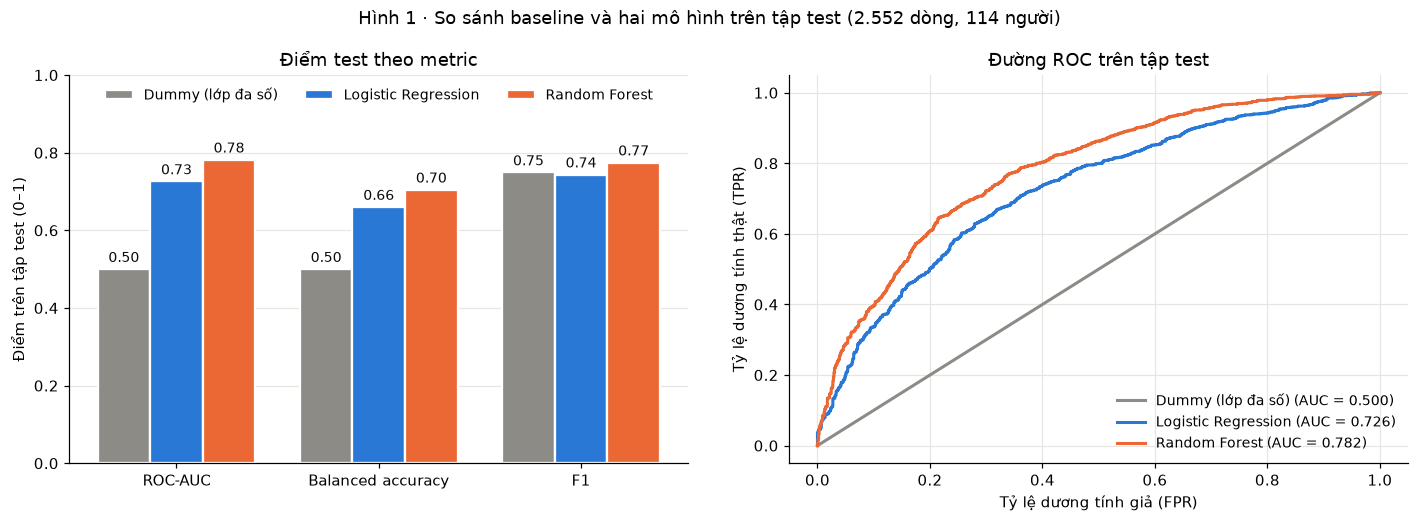

In [12]:
# Hình 1: so sánh baseline và hai mô hình trên tập test
INK, MUTED = "#0b0b0b", "#52514e"
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#8c8b86"
MODEL_COLORS = {"Dummy (lớp đa số)": GRAY, "Logistic Regression": BLUE, "Random Forest": ORANGE}
PLOT_METRICS = {"test_roc_auc": "ROC-AUC", "test_balanced_accuracy": "Balanced accuracy", "test_f1": "F1"}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# Trái: ba metric trên test
ax = axes[0]
bar_width = 0.26
x = np.arange(len(PLOT_METRICS))
for k, name in enumerate(MODELS):
    values = test_table.loc[name, list(PLOT_METRICS)].to_numpy(dtype=float)
    position = x + (k - 1) * bar_width
    ax.bar(position, values, width=bar_width, color=MODEL_COLORS[name], edgecolor="white", linewidth=1.5, label=name)
    for xpos, value in zip(position, values):
        ax.text(xpos, value + 0.01, f"{value:.2f}", ha="center", va="bottom", fontsize=9, color=INK)
ax.set_xticks(x, PLOT_METRICS.values())
ax.set_ylim(0, 1)
ax.set_ylabel("Điểm trên tập test (0–1)")
ax.set_title("Điểm test theo metric")
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, loc="upper center", ncol=3, fontsize=9)

# Phải: đường ROC trên test
ax = axes[1]
for name in MODELS:
    fpr, tpr, _ = roc_curve(y_test, test_proba[name])
    ax.plot(fpr, tpr, color=MODEL_COLORS[name], linewidth=2,
            label=f"{name} (AUC = {test_table.loc[name, 'test_roc_auc']:.3f})")
ax.set_xlabel("Tỷ lệ dương tính giả (FPR)")
ax.set_ylabel("Tỷ lệ dương tính thật (TPR)")
ax.set_title("Đường ROC trên tập test")
ax.legend(frameon=False, loc="lower right", fontsize=9)

fig.suptitle("Hình 1 · So sánh baseline và hai mô hình trên tập test (2.552 dòng, 114 người)")
fig.tight_layout()
fig.savefig(FIG_DIR / "q6_fig1_model_comparison.png", dpi=150)
plt.show()

## 6. Phân tích lỗi

Phần này chỉ xét **mô hình đã chọn**, trên tập test, ở ngưỡng 0,5. Hai loại lỗi:

- **Dương tính giả (FP):** mô hình đoán sẽ nhận nhưng người dùng từ chối → gửi coupon cho người không muốn (gây phiền, tốn lượt hiển thị).
- **Âm tính giả (FN):** mô hình đoán sẽ từ chối nhưng người dùng muốn nhận → bỏ lỡ một lượt coupon có khả năng thành công.

Ba góc nhìn: (a) ma trận nhầm lẫn tổng thể, (b) tỷ lệ lỗi theo nhóm `coupon`, `passanger`, `destination`, (c) lỗi theo khoảng xác suất dự đoán và một số dòng sai cụ thể.

TN = 628, FP = 396, FN = 312, TP = 1216
FPR = FP / (FP + TN) = 38.7%;  FNR = FN / (FN + TP) = 20.4%


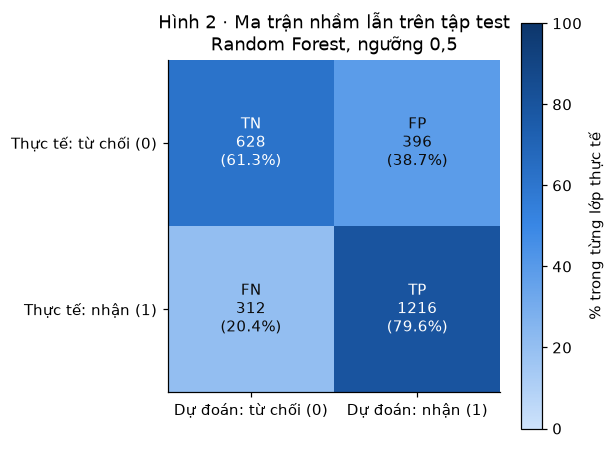

In [13]:
# Hình 2: ma trận nhầm lẫn của mô hình đã chọn trên tập test
from matplotlib.colors import LinearSegmentedColormap
SEQ_BLUE = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])

selected_pred = test_pred[selected_name]
selected_proba = test_proba[selected_name]

cm = confusion_matrix(y_test, selected_pred)            # hàng: thực tế 0/1; cột: dự đoán 0/1
cm_row_pct = cm / cm.sum(axis=1, keepdims=True) * 100   # % theo từng hàng (từng lớp thực tế)
tn, fp, fn, tp = cm.ravel()
print(f"TN = {tn}, FP = {fp}, FN = {fn}, TP = {tp}")
print(f"FPR = FP / (FP + TN) = {fp / (fp + tn):.1%};  FNR = FN / (FN + TP) = {fn / (fn + tp):.1%}")

fig, ax = plt.subplots(figsize=(5.6, 4.6))
image = ax.imshow(cm_row_pct, cmap=SEQ_BLUE, vmin=0, vmax=100)
ax.grid(False)
CELL_NAMES = [["TN", "FP"], ["FN", "TP"]]
for i in range(2):
    for j in range(2):
        text_color = "white" if cm_row_pct[i, j] >= 50 else INK
        ax.text(j, i, f"{CELL_NAMES[i][j]}\n{cm[i, j]}\n({cm_row_pct[i, j]:.1f}%)", ha="center", va="center", color=text_color)
ax.set_xticks([0, 1], ["Dự đoán: từ chối (0)", "Dự đoán: nhận (1)"])
ax.set_yticks([0, 1], ["Thực tế: từ chối (0)", "Thực tế: nhận (1)"])
ax.set_title(f"Hình 2 · Ma trận nhầm lẫn trên tập test\n{selected_name}, ngưỡng 0,5")
fig.colorbar(image, ax=ax, label="% trong từng lớp thực tế")
fig.tight_layout()
fig.savefig(FIG_DIR / "q6_fig2_confusion_matrix.png", dpi=150)
plt.show()

In [14]:
# Bảng lỗi theo nhóm
errors = X_test.copy()
errors["y_true"] = y_test.to_numpy()
errors["y_pred"] = selected_pred
errors["proba"] = selected_proba
errors["correct"] = errors["y_true"] == errors["y_pred"]
errors["is_fp"] = (errors["y_true"] == 0) & (errors["y_pred"] == 1)
errors["is_fn"] = (errors["y_true"] == 1) & (errors["y_pred"] == 0)
errors["is_neg"] = errors["y_true"] == 0
errors["is_pos"] = errors["y_true"] == 1


def error_table(data, by):
    """Số dòng, tỷ lệ nhận thực tế, accuracy, FPR và FNR (đều tính theo %) cho từng nhóm."""
    grouped = data.groupby(by)
    table = pd.DataFrame({
        "n": grouped.size(),
        "ty_le_nhan_thuc_te": grouped["y_true"].mean() * 100,
        "ty_le_du_doan_nhan": grouped["y_pred"].mean() * 100,
        "accuracy": grouped["correct"].mean() * 100,
        "FPR": grouped["is_fp"].sum() / grouped["is_neg"].sum() * 100,   # FP / số dòng thực tế từ chối
        "FNR": grouped["is_fn"].sum() / grouped["is_pos"].sum() * 100,   # FN / số dòng thực tế nhận
    })
    return table.round(1).sort_values("accuracy")


error_tables = {}
for by in ["coupon", "passanger", "destination"]:
    error_tables[by] = error_table(errors, by)
    print(f"Lỗi theo {by} (xếp theo accuracy tăng dần)")
    display(error_tables[by])

Lỗi theo coupon (xếp theo accuracy tăng dần)


,n,ty_le_nhan_thuc_te,ty_le_du_doan_nhan,accuracy,FPR,FNR
coupon,,,,,,
Bar,390,47.4,33.8,63.3,22.0,53.0
Restaurant(20-50),302,44.7,37.1,64.6,25.1,48.1
Coffee House,821,49.8,55.1,72.8,32.3,22.0
Restaurant(<20),562,76.0,81.9,77.0,60.0,11.2
Carry out & Take away,477,78.0,95.6,77.8,90.5,3.0


Lỗi theo passanger (xếp theo accuracy tăng dần)


,n,ty_le_nhan_thuc_te,ty_le_du_doan_nhan,accuracy,FPR,FNR
passanger,,,,,,
Alone,1484,55.3,54.0,70.2,31.9,28.0
Partner,193,56.5,73.1,72.0,51.2,10.1
Kid(s),198,58.6,50.0,74.2,20.7,29.3
Friend(s),677,71.3,84.2,76.2,63.9,7.7


Lỗi theo destination (xếp theo accuracy tăng dần)


,n,ty_le_nhan_thuc_te,ty_le_du_doan_nhan,accuracy,FPR,FNR
destination,,,,,,
Home,642,54.2,48.0,67.3,28.9,35.9
Work,649,50.5,49.6,70.1,29.3,30.5
No Urgent Place,1261,67.6,77.9,75.9,53.1,10.2


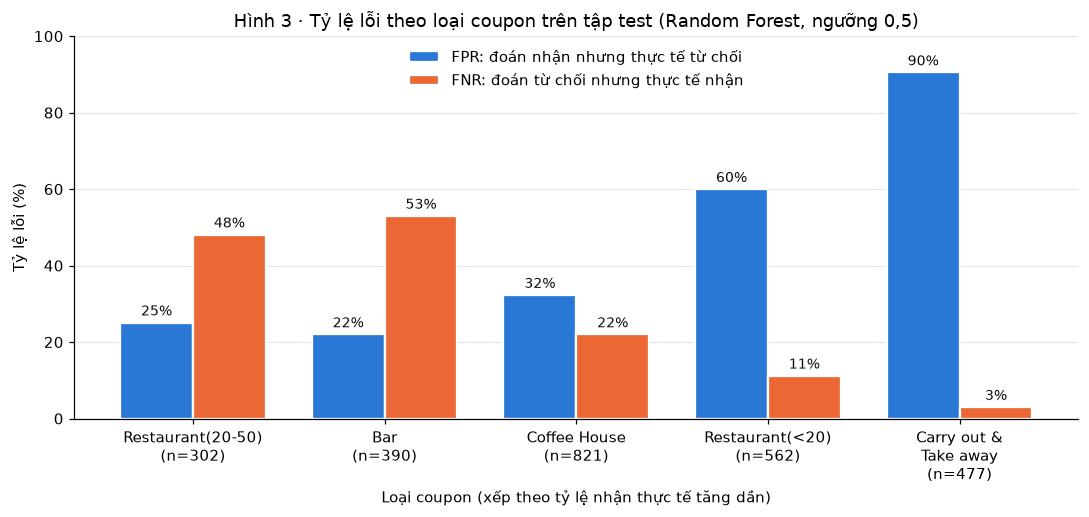

In [15]:
# Hình 3: FPR và FNR theo loại coupon
by_coupon = error_tables["coupon"].sort_values("ty_le_nhan_thuc_te")
labels = []
for name, n in zip(by_coupon.index, by_coupon["n"]):
    wrapped_name = name.replace(" & ", " &\n")          # xuống dòng cho nhãn dài
    labels.append(f"{wrapped_name}\n(n={n})")

fig, ax = plt.subplots(figsize=(10, 4.8))
x = np.arange(len(by_coupon))
bar_width = 0.38
for offset, column, color, label in [(-0.5, "FPR", BLUE, "FPR: đoán nhận nhưng thực tế từ chối"),
                                     (0.5, "FNR", ORANGE, "FNR: đoán từ chối nhưng thực tế nhận")]:
    position = x + offset * bar_width
    ax.bar(position, by_coupon[column], width=bar_width, color=color, edgecolor="white", linewidth=1.5, label=label)
    for xpos, value in zip(position, by_coupon[column]):
        ax.text(xpos, value + 1, f"{value:.0f}%", ha="center", va="bottom", fontsize=9, color=INK)
ax.set_xticks(x, labels)
ax.set_ylim(0, 100)
ax.set_ylabel("Tỷ lệ lỗi (%)")
ax.set_xlabel("Loại coupon (xếp theo tỷ lệ nhận thực tế tăng dần)")
ax.set_title(f"Hình 3 · Tỷ lệ lỗi theo loại coupon trên tập test ({selected_name}, ngưỡng 0,5)")
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, loc="upper center")
fig.tight_layout()
fig.savefig(FIG_DIR / "q6_fig3_errors_by_coupon.png", dpi=150)
plt.show()

In [16]:
# Lỗi theo khoảng xác suất dự đoán: mô hình sai ở vùng nào, và xác suất có khớp tỷ lệ thật không?
PROBA_BINS = [0, 0.3, 0.4, 0.5, 0.6, 0.7, 1.0]
errors["proba_bin"] = pd.cut(errors["proba"], bins=PROBA_BINS, include_lowest=True)
by_proba = errors.groupby("proba_bin", observed=True).agg(
    n=("y_true", "size"),
    xac_suat_du_doan_tb=("proba", "mean"),
    ty_le_nhan_thuc_te=("y_true", "mean"),
    accuracy=("correct", "mean"),
)
display(by_proba.round(3))

# Ví dụ lỗi, chọn theo quy tắc cố định chứ không chọn tay: 5 FP và 5 FN mà mô hình tự tin nhất
EXAMPLE_COLS = ["coupon", "expiration", "destination", "passanger", "time", "age", "income", "proba", "y_true", "y_pred"]
print("5 dương tính giả tự tin nhất (xác suất dự đoán cao nhưng thực tế từ chối):")
display(errors[errors["is_fp"]].nlargest(5, "proba")[EXAMPLE_COLS].round(3))
print("5 âm tính giả tự tin nhất (xác suất dự đoán thấp nhưng thực tế nhận):")
display(errors[errors["is_fn"]].nsmallest(5, "proba")[EXAMPLE_COLS].round(3))

,n,xac_suat_du_doan_tb,ty_le_nhan_thuc_te,accuracy
proba_bin,,,,
"(-0.001, 0.3]",420,0.207,0.186,0.814
"(0.3, 0.4]",247,0.353,0.429,0.571
"(0.4, 0.5]",273,0.452,0.469,0.531
"(0.5, 0.6]",354,0.551,0.571,0.571
"(0.6, 0.7]",440,0.651,0.736,0.736
"(0.7, 1.0]",818,0.798,0.844,0.844


5 dương tính giả tự tin nhất (xác suất dự đoán cao nhưng thực tế từ chối):


,coupon,expiration,destination,passanger,time,age,income,proba,y_true,y_pred
5328,Restaurant(<20),1d,No Urgent Place,Friend(s),6PM,26,$25000 - $37499,0.949,0,1
1633,Restaurant(<20),1d,No Urgent Place,Alone,2PM,26,$37500 - $49999,0.932,0,1
1688,Carry out & Take away,1d,No Urgent Place,Friend(s),2PM,46,$100000 or More,0.921,0,1
5481,Restaurant(<20),1d,No Urgent Place,Friend(s),6PM,41,$12500 - $24999,0.905,0,1
5920,Restaurant(<20),1d,No Urgent Place,Friend(s),6PM,21,Less than $12500,0.897,0,1


5 âm tính giả tự tin nhất (xác suất dự đoán thấp nhưng thực tế nhận):


,coupon,expiration,destination,passanger,time,age,income,proba,y_true,y_pred
10204,Bar,1d,Work,Alone,7AM,50plus,Less than $12500,0.076,1,0
12437,Bar,1d,No Urgent Place,Kid(s),6PM,50plus,$37500 - $49999,0.084,1,0
10197,Bar,1d,Home,Alone,6PM,50plus,Less than $12500,0.088,1,0
10192,Bar,1d,No Urgent Place,Alone,2PM,50plus,Less than $12500,0.094,1,0
8104,Bar,1d,No Urgent Place,Kid(s),6PM,41,$62500 - $74999,0.102,1,0


**Nhận xét về lỗi (Random Forest, tập test, ngưỡng 0,5).**

1. **Mô hình nghiêng về đoán "nhận".** Trong 708 lỗi có 396 FP và 312 FN. Tính theo tỷ lệ: 38,7% số dòng thực tế từ chối bị đoán nhầm là nhận (FPR), trong khi chỉ 20,4% số dòng thực tế nhận bị bỏ sót (FNR).
2. **Loại lỗi đổi chiều theo loại coupon (Hình 3).** Với coupon vốn được nhận nhiều, mô hình gần như luôn đoán "nhận": ở **Carry out & Take away** nó đoán nhận cho 95,6% số dòng, nên FNR chỉ 3,0% nhưng FPR lên tới **90,5%** (95 trong 105 dòng từ chối bị đoán sai); **Restaurant(<20)** có FPR 60,0%. Ngược lại, với coupon vốn ít được nhận thì mô hình bỏ sót người muốn nhận: **Bar** có FNR **53,0%** và **Restaurant(20-50)** có FNR 48,1%; đây cũng là hai nhóm có accuracy thấp nhất (63,3% và 64,6%). Coffee House, nhóm đông nhất (n = 821), có hai loại lỗi cân bằng hơn (32,3% và 22,0%).
3. **Cùng một quy luật ở `passanger` và `destination`.** Đi với bạn bè (tỷ lệ nhận thực tế 71,3%) có FPR 63,9%; không có nơi cần đến gấp (67,6%) có FPR 53,1%. Tức là mô hình học tốt *mức nền* của từng bối cảnh, nhưng phân biệt kém giữa những người **trong cùng một bối cảnh thuận lợi**. Nhóm `Partner` (n = 193) và `Kid(s)` (n = 198) có ít dòng nên tỷ lệ lỗi của hai nhóm này kém chắc chắn hơn.
4. **Lỗi dồn vào vùng xác suất lưng chừng.** Khi mô hình tự tin, nó thường đúng: accuracy 81,4% ở xác suất ≤ 0,3 (n = 420) và 84,4% ở xác suất > 0,7 (n = 818). Trong khoảng 0,3–0,6 (874 dòng, 34% tập test) accuracy chỉ 53–57%, gần như tung đồng xu. Xác suất dự đoán cũng khá sát tỷ lệ thật trong từng khoảng (ví dụ dự đoán trung bình 0,21 so với thực tế 18,6%; 0,80 so với 84,4%), nên có thể dùng nó như một điểm ưu tiên.
5. **Ví dụ lỗi tự tin nhất.** 4/5 dương tính giả tự tin nhất là coupon Restaurant(<20) hạn 1 ngày, không có nơi cần đến gấp, phần lớn đang đi cùng bạn bè: bối cảnh "lý tưởng" theo mô hình nhưng người đó vẫn từ chối, vì lý do không nằm trong dữ liệu. Cả 5 âm tính giả tự tin nhất đều là coupon Bar, 4/5 thuộc nhóm tuổi `50plus`: khớp với Q5 (nhóm lớn tuổi ít nhận coupon Bar), nhưng vẫn có những cá nhân đi ngược xu hướng nhóm mà mô hình không nhận ra.

**Chi phí của hai loại lỗi.** Nếu gửi một coupon gần như không tốn gì thì FP ít đáng lo và ngưỡng 0,5 (hoặc thấp hơn) là hợp lý. Nếu việc làm phiền người lái có giá (người dùng tắt thông báo, bỏ ứng dụng) thì nên nâng ngưỡng, đặc biệt với Carry out và Restaurant(<20), nơi mô hình hiện gần như gửi cho tất cả. Việc chọn ngưỡng phải dựa trên chi phí thật, điều mà bộ dữ liệu khảo sát này không cung cấp.

## 7. Diễn giải mô hình và trả lời câu hỏi

**Permutation importance.** Với từng cột gốc, xáo trộn ngẫu nhiên giá trị của cột đó trong tập test (giữ nguyên các cột khác), cho mô hình dự đoán lại và đo ROC-AUC giảm bao nhiêu. Cột nào bị xáo mà điểm giảm nhiều thì mô hình dựa nhiều vào cột đó. Phép đo chạy trên cả `Pipeline` nên kết quả tính theo **22 cột gốc**, không theo từng cột one-hot. Mỗi cột được xáo 10 lần để có độ lệch chuẩn.

Tập test ở đây chỉ dùng để *diễn giải* mô hình đã chốt, không dùng để chọn hay sửa mô hình.

In [17]:
importance = permutation_importance(selected_model, X_test, y_test, scoring="roc_auc",
                                    n_repeats=10, random_state=SEED, n_jobs=-1)
importance_table = pd.DataFrame({
    "giam_roc_auc_tb": importance.importances_mean,
    "do_lech_chuan": importance.importances_std,
}, index=FEATURE_COLS).sort_values("giam_roc_auc_tb", ascending=False)
display(importance_table.round(4))

,giam_roc_auc_tb,do_lech_chuan
coupon,0.1570,0.0093
CoffeeHouse,0.0577,0.0038
expiration,0.0493,0.0047
Bar,0.0175,0.0026
destination,0.0149,0.0024
time,0.0089,0.0021
passanger,0.0065,0.0017
toCoupon_GEQ15min,0.0026,0.0014
toCoupon_GEQ25min,0.0017,0.0004
CarryAway,0.0016,0.0007


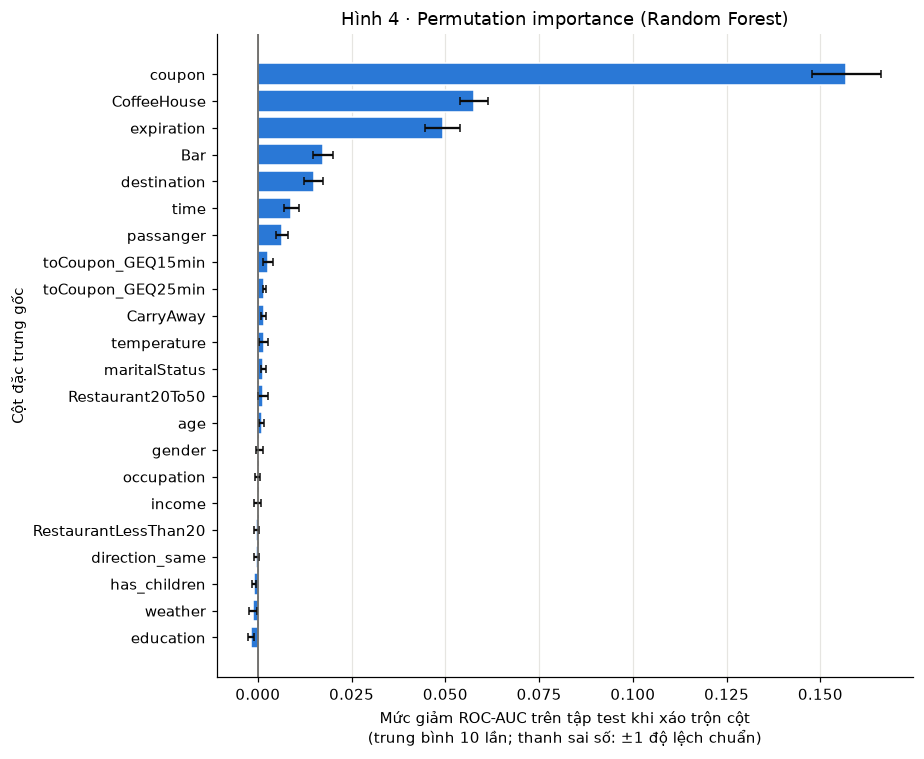

In [18]:
# Hình 4: permutation importance của mô hình đã chọn
plot_data = importance_table.iloc[::-1]     # đảo thứ tự để cột quan trọng nhất nằm trên cùng

fig, ax = plt.subplots(figsize=(8.5, 7))
ax.barh(plot_data.index, plot_data["giam_roc_auc_tb"], xerr=plot_data["do_lech_chuan"],
        color=BLUE, edgecolor="white", linewidth=1, ecolor=INK, capsize=2.5)
ax.axvline(0, color=MUTED, linewidth=1)
ax.set_xlabel("Mức giảm ROC-AUC trên tập test khi xáo trộn cột\n(trung bình 10 lần; thanh sai số: ±1 độ lệch chuẩn)")
ax.set_ylabel("Cột đặc trưng gốc")
ax.set_title(f"Hình 4 · Permutation importance ({selected_name})")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "q6_fig4_permutation_importance.png", dpi=150)
plt.show()

**Đọc Hình 4.**

- **`coupon` quan trọng vượt trội:** xáo cột này làm ROC-AUC giảm 0,157 (± 0,009), gấp gần ba lần cột đứng thứ hai. Loại coupon quyết định phần lớn khả năng được nhận.
- **Thói quen khớp với coupon đứng kế tiếp:** `CoffeeHouse` (0,058) và `Bar` (0,018). Hai cột này chỉ có ích khi đi cùng đúng loại coupon, tức là một *tương tác* giữa coupon và thói quen. Random Forest tự học được tương tác đó, còn Logistic Regression thì không nếu không thêm biến tương tác bằng tay; đây là lời giải thích hợp lý cho khoảng cách 0,056 ROC-AUC giữa hai mô hình.
- **`expiration` (0,049), `destination` (0,015), `time` (0,009), `passanger` (0,007)** là nhóm bối cảnh có đóng góp rõ.
- **Nhân khẩu học gần như không đóng góp:** `age` chỉ 0,001 và `income` xấp xỉ 0, cùng với `gender`, `occupation`, `education`, `has_children`. Các giá trị âm rất nhỏ (ví dụ `education` −0,002) nằm trong mức nhiễu của phép xáo trộn.

**Liên hệ với Q5.** Q5 thấy khoảng cách theo tuổi giảm đi khi kiểm soát thói quen và thu nhập gần như không có liên hệ ổn định. Mô hình ở đây cho cùng một bức tranh từ góc khác: khi đã biết loại coupon, thói quen và bối cảnh, tuổi và thu nhập hầu như không giúp dự đoán thêm.

**Thận trọng khi diễn giải.** Permutation importance đo việc *mô hình này* dựa vào cột nào để dự đoán, không đo quan hệ nhân quả. Các cột hồ sơ có tương quan với nhau (tuổi, hôn nhân, nghề nghiệp), nên khi xáo một cột, mô hình vẫn lấy lại được một phần thông tin từ các cột còn lại; importance thấp vì thế không có nghĩa là cột đó không liên hệ với `Y`.

### Trả lời câu hỏi Q6

**Có.** Chỉ dùng thông tin biết trước lúc hiển thị coupon, mô hình Random Forest dự đoán ý định chấp nhận tốt hơn rõ rệt so với baseline, trên những người chưa từng xuất hiện lúc huấn luyện: ROC-AUC **0,782** (CI 95%: 0,756–0,808) so với 0,500, balanced accuracy **0,705** so với 0,500, accuracy **72,3%** so với 59,9%.

**Mức độ hữu ích: vừa phải, và hữu ích nhất khi dùng để xếp hạng.** Ở ngưỡng 0,5 mô hình vẫn sai 27,7% số dòng. Nhưng điểm xác suất tách khá tốt hai đầu: trong 818 dòng (32% tập test) có xác suất dự đoán trên 0,7, có 84,4% thực sự nhận; trong 420 dòng (16%) có xác suất từ 0,3 trở xuống, chỉ 18,6% nhận. Một quy tắc thực tế có thể là: ưu tiên gửi ở nhóm điểm cao, không gửi ở nhóm điểm thấp, và ở vùng lưng chừng 0,3–0,6 thì đừng tin vào mô hình.

**Mô hình dựa vào đâu.** Chủ yếu là *gửi coupon gì* (loại, thời hạn), *người đó có thói quen khớp không* (đặc biệt cà phê và bar), và *bối cảnh chuyến đi* (điểm đến, giờ, người đi cùng). Nhân khẩu học đóng góp rất ít.

**Mô hình yếu ở đâu.** Nó phân biệt kém giữa những người trong cùng một bối cảnh: gần như luôn đoán "nhận" với coupon đồ ăn rẻ (FPR 90,5% ở Carry out) và bỏ sót hơn một nửa số người muốn nhận coupon Bar (FNR 53,0%).

## 8. Hạn chế và checklist tái lập

**Hạn chế.**

- **Dữ liệu khảo sát.** `Y` là ý định trong kịch bản giả định, người trả lời đến từ Amazon Mechanical Turk. Điểm số ở đây không nói mô hình sẽ hoạt động thế nào với hành vi đổi coupon thật hay với tập người dùng khác.
- **ID người trả lời là suy ra.** Cách chia theo người dựa trên giả định "trùng hồ sơ = cùng người". Nếu giả định sai ở một số trường hợp, vẫn có thể còn chút rò rỉ giữa train và test.
- **Giả định về thời điểm dự đoán.** Mô hình coi hồ sơ và thói quen là đã biết trước. Với người dùng hoàn toàn mới chưa khai hồ sơ (cold start), các cột quan trọng như `CoffeeHouse`, `Bar` sẽ thiếu và hiệu năng sẽ thấp hơn con số báo cáo.
- **Tập test nhỏ về số người.** 114 người; CI của ROC-AUC rộng khoảng ±0,026. Các bảng lỗi theo nhóm nhỏ (`Partner`, `Kid(s)`, khoảng 200 dòng) còn kém chắc chắn hơn.
- **Chỉ một lần chia train/test.** Kết quả phụ thuộc vào `random_state = 42`; một lần chia khác sẽ cho con số hơi khác (độ lệch chuẩn giữa các fold CV, khoảng 0,01, cho biết cỡ dao động).
- **Ngưỡng 0,5 chưa được tối ưu** theo chi phí thật của FP và FN, vì dữ liệu không có thông tin chi phí.
- **Phạm vi mô hình.** Chỉ thử hai họ mô hình với lưới siêu tham số nhỏ; chưa thử gradient boosting hay thêm biến tương tác cho Logistic Regression.
- **Diễn giải.** Permutation importance không phải quan hệ nhân quả và bị ảnh hưởng bởi tương quan giữa các cột.

**Checklist.**

- [x] Người dùng, thời điểm dự đoán, nhãn và kiểm kê rò rỉ được nêu rõ (phần 1); 4 cột bị loại kèm lý do.
- [x] Chia train/test theo người trả lời; rủi ro lặp người được đo trực tiếp (ROC-AUC bị thổi phồng 0,043 nếu chia theo dòng).
- [x] Baseline + 2 mô hình, dùng chung một cách chia và chung các fold CV.
- [x] Toàn bộ tiền xử lý nằm trong `Pipeline` (`ColumnTransformer` + `SimpleImputer` + `OneHotEncoder`).
- [x] Tinh chỉnh bằng `GridSearchCV` chỉ trên train; mô hình được chốt trước khi chấm test; test chấm một lần.
- [x] Metric chính (ROC-AUC) được chọn và giải thích trước khi xem kết quả.
- [x] Phân tích lỗi theo nhóm, theo khoảng xác suất và ví dụ cụ thể; 4 biểu đồ.
- [x] Diễn giải bằng permutation importance và trả lời câu hỏi ban đầu.
- [x] `random_state = 42` ở mọi bước ngẫu nhiên; phiên bản thư viện được in ở đầu notebook; notebook chạy được từ kernel mới (Restart & Run All).